In [256]:
# https://pyhank.readthedocs.io/en/latest/auto_examples/simple_example.html

#pip install pyhank
import numpy as np
from scipy.interpolate import interp1d
#from scipy.fft import fht
import scipy.special
from pyhank import HankelTransform

### Useful functions & G-S

In [257]:
def KtoR(k, waveLength, focalLength):
    return waveLength * focalLength * k / (2 * np.pi)

def RtoK(r, waveLength, focalLength):
    return 2 * np.pi * r / (waveLength * focalLength)

In [258]:
def MSE_w(goalProfile, iterProfile, weights):

    # Donem mes pes als valors mes allunyats del centre, ja que son els que influiran 
    # mes en fer la revolucio del perfil

    return np.sum(weights * (goalProfile - iterProfile)**2)/(np.sum(weights * goalProfile**2) + 1e-15)

def GerchbergSaxton(inputProfile, goalProfile, transformer, radius = 100, maxiter = 10000, errMin = 1e-4):

    # define transformer & scale
    N = len(goalProfile)
    r = transformer.r
    kr = transformer.kr

    # normalize target intensity
    P_in = 2 * np.pi * np.trapezoid(np.abs(inputProfile)**2 * r, r)
    P_goal = 2 * np.pi * np.trapezoid(np.abs(goalProfile)**2 * r, r)
    goalProfile *= np.sqrt(P_in/P_goal)


    #a = 1/3
    #f = scipy.special.jv(1, transformer.r * a) / (transformer.r * a)

    a = 1
    n = 2
    testfit = np.array([8*item*1e2 * (item*1e2)**n / ((item * 1e2)**n + (a)**n) - 2.5 for item in r])
    # define initial DOE
    U_DOE = np.exp(1j * testfit)

    # definim ponderacions per MSE
    #slope = 1
    #weights = np.linspace(1, N*slope, N)
    weights = kr * np.gradient(kr) # gradient per no uniforme

    # CHAT---------------------------------------

    # Output of initial field
    U_initial = transformer.qdht(inputProfile)

    # Integration weights in Hankel frequency coordinates
    weights = kr * np.gradient(kr)

    # Match target power to the initial transformed field
    P_found = np.sum(weights * np.abs(U_initial)**2)
    P_goal = np.sum(weights * np.abs(goalProfile)**2)

    goalProfile = goalProfile * np.sqrt(P_found / P_goal)

    # ------------------

    for i in range(maxiter):

        # --- DOE PLANE

        # apply DOE phase
        U_tot = inputProfile * U_DOE

        # propagate to focal plane
        U_image = transformer.qdht(U_tot)

        # ---- IMAGE PLANE

        # Find new intensity
        U_im_abs = np.abs(U_image)
        I_found = U_im_abs**2

        # check for MSE with radial weighting
        error = MSE_w(goalProfile, U_im_abs, weights)

        # replace amplitude, retain phase
        U_image = goalProfile * np.exp(1j * np.angle(U_image))

        # Check for flatness
        #flatness = (max(I) - min(I))/(max(I) + min(I))

        if error < errMin:
            print("Converged with error < errMin")
            break

        # go back to DOE
        U_DOE = transformer.iqdht(U_image)
        U_DOE = np.exp(1j * np.angle(U_DOE))

    print("# iterations = ", i)
    print("Error = ", error)
    return U_DOE

### Class definition

In [277]:
class GS_DOE:
    def __init__(self, params):
        self.setParams(params)

    def setParams(self, params):
        self.fl = params["fl"]
        self.wl = params["wl"]
        self.rmax = params["rmax"]
        self.N = params["N"]
        self.w0 = params["w0"]
        self.wgoal = params["wgoal"]

    def setFocal(self, focal):
        self.fl = focal

    def setWl(self, wl):
        self.wl = wl

    def setW0(self, w0):
        self.w0 = w0

    def setrmax(self, rmax):
        self.rmax = rmax

    def makeProfiles(self, p = 3):
        self.transformer = HankelTransform(order=0, max_radius=rmax, n_points=N)
        self.r = self.transformer.r
        self.kr = self.transformer.kr
        
        # define input intensity profile
        self.inputInt = np.exp(-(self.r/self.w0)**2)
        self.inputAmp = np.sqrt(self.inputInt)

        # UNUSED, forma general per separacio irregular
        U_in = interp1d(
            rads, inputAmp,
            bounds_error=False,
            fill_value=0
        )(r)

        # Convert spatial frequency to physical focal-plane radius
        self.rho = self.wl * self.fl * self.transformer.kr / (2*np.pi)

        self.goalProfile = np.exp(-0.5*(self.rho/self.wgoal)**(2*p))


    def showInputs(self):
        fig, ax = plt.subplots(1, 1, figsize = (6, 4))
        ax.plot(self.r*1e2, self.inputAmp, label = "Input amplitude")
        ax.plot(self.r*1e2, self.goalProfile, label = "Goal amplitude")
        ax.legend(fontsize = 14)
        ax.set_xlabel("Radius (cm)", fontsize = 14)
        ax.set_ylabel("I/I$_0$", fontsize = 14)
        ax.set_xlim(0, np.max(self.r)*1e2)
        plt.show()

    def makeDOE(self):
        self.DOE = GerchbergSaxton(self.inputAmp, self.goalProfile, self.transformer, radius = self.rmax, maxiter = 10000)

    def showResults(self):
        fig, axs = plt.subplots(1, 2, figsize = (12, 4))

        testfit = [8*item*1e2 * (item*1e2)**2 / ((item * 1e2)**2 + 1) - 2.5 for item in self.r]
        axs[0].plot(self.r*1e2, np.unwrap(np.angle(self.DOE)), label = "DOE")
        axs[0].plot(self.r*1e2, testfit, label = "Initial fit")
        axs[0].set_title("DOE phase profile")
        axs[0].set_xlabel("r (cm)", fontsize = 14)
        axs[0].set_ylabel("Phase (rad)", fontsize = 14)
        axs[0].set_xlim(0, np.max(self.r)*1e2)
        axs[0].legend()

        # test DOE
        U_converged = self.inputAmp * self.DOE
        U_image = self.transformer.qdht(U_converged)

        normImage = np.abs(U_image) / max(np.abs(U_image))

        axs[1].plot(self.rho*1e2, normImage, label = "Converged")
        #axs[1].plot(kr, goalProfile, label = "Goal")
        axs[1].set_title("Image profile")
        axs[1].set_xlabel("Distance to center (cm)", fontsize = 14)
        axs[1].set_ylabel("I/I$_0$", fontsize = 14)
        axs[1].set_xlim(0, max(self.rho*100/5))
        fig.show()

    def getDOE(self):
        return self.DOE

## DOE designer (Circular symmetry)

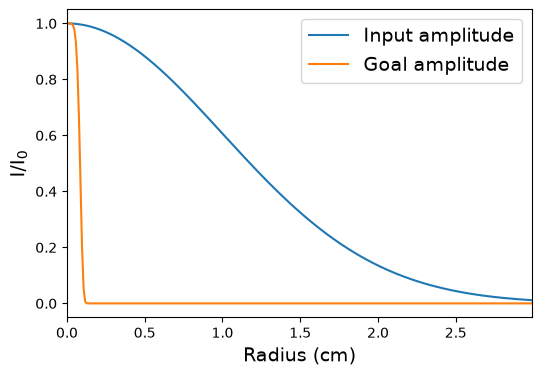

Converged with error < errMin
# iterations =  14
Error =  9.905232435168567e-05


C:\Users\PC\AppData\Local\Temp\ipykernel_12460\12492607.py:84: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


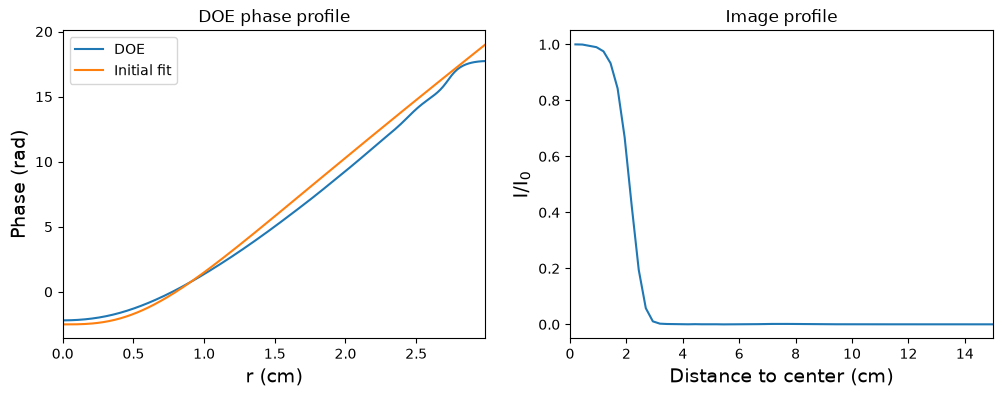

In [279]:
f = 300e9 # Hz

params = {
    "fl": 15e-2, # cm
    "wl": 3e8/f,
    "rmax": 30e-2, # cm
    "N": 300,
    "w0": 0.01, # cm
    "wgoal": 0.02 # cm
}

DOE_maker = GS_DOE(params)
DOE_maker.makeProfiles(p = 3)
DOE_maker.showInputs()
DOE_maker.makeDOE()
DOE_maker.showResults()